# ATRS requirements study — publication-oriented computational audit
Project 19 · Team On Top · Target journal: *Requirements Engineering*

**Scope:** reproducibility and synthetic-data audit, not an empirical evaluation of LLM performance. All existing CSV inputs are retained unchanged. The simulated ratings and template-derived requirements cannot support empirical claims. All statistical outputs below are illustrative diagnostics only.

## 1. Environment and input locations

In [1]:
from pathlib import Path
import sys, json, warnings, re, math
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

SEED = 42
np.random.seed(SEED)
ROOT = Path(".").resolve()
if not (ROOT / "data").exists() and (ROOT.parent / "data").exists():
    ROOT = ROOT.parent
DATA_DIR = ROOT / "data"
OUT_DIR = ROOT / "outputs"
OUT_DIR.mkdir(exist_ok=True)

print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__, "| numpy:", np.__version__)
print("Expected input directory:", DATA_DIR.resolve())
print("Output directory:", OUT_DIR.resolve())
import scipy, sklearn, matplotlib, hashlib, zipfile
from sklearn.metrics import cohen_kappa_score
print("Versions:", scipy.__version__, sklearn.__version__, matplotlib.__version__)
try:
    from IPython.display import display, Image
except ImportError:
    def display(*args, **kwargs):
        for a in args:
            print(a)
    class Image:
        def __init__(self, filename=None, **kwargs):
            self.filename = filename
import inspect


Python: 3.14.0
pandas: 2.3.3 | numpy: 2.4.2
Expected input directory: C:\Users\Yashika\Downloads\SEM 2\AI\atrs_project\data
Output directory: C:\Users\Yashika\Downloads\SEM 2\AI\atrs_project\outputs
Versions: 1.18.1 1.9.1 3.10.8


## 2. Upload / locate raw files
Place the required CSVs in `data/` beside this notebook, or use the upload cell below in Colab. Do not use the old `demo_data` directory unless it is confirmed to contain the same frozen dataset.

In [2]:
# Detect local datasets or provide Colab upload fallback
local_csvs = list(DATA_DIR.glob("*.csv")) if DATA_DIR.exists() else []

if local_csvs:
    print(f"Located {len(local_csvs)} dataset files in {DATA_DIR.resolve()}: {[f.name for f in sorted(local_csvs)]}")
else:
    try:
        from google.colab import files
        print("Running in Google Colab. Please upload dataset CSV files:")
        uploaded = files.upload()
        DATA_DIR.mkdir(exist_ok=True)
        for name, content in uploaded.items():
            (DATA_DIR / name).write_bytes(content)
        print("Uploaded:", list(uploaded))
    except ImportError:
        print(f"CSV files not found in {DATA_DIR.resolve()}. Please place required CSV files in ./data/.")


Located 11 dataset files in C:\Users\Yashika\Downloads\SEM 2\AI\atrs_project\data: ['annotation_key.csv', 'annotations_A.csv', 'annotations_B.csv', 'annotations_template_A.csv', 'annotations_template_B.csv', 'atrs_records.csv', 'candidates.csv', 'ratings.csv', 'records.csv', 'requirements.csv', 'usage_log.csv']


In [3]:
def read_csv_if_present(name):
    path = DATA_DIR / name
    if not path.exists():
        print(f"MISSING: {path}")
        return None
    df = pd.read_csv(path)
    print(f"Loaded {name}: {len(df):,} rows × {len(df.columns)} columns")
    return df

records = read_csv_if_present("records.csv")
requirements = read_csv_if_present("requirements.csv")
ratings = read_csv_if_present("ratings.csv")

# If ratings.csv was missing, assemble from annotations_A, annotations_B, and key
if ratings is None and (DATA_DIR / "annotation_key.csv").exists() and (DATA_DIR / "annotations_A.csv").exists():
    print("Constructing ratings from annotations_A, annotations_B, and key...")
    key = pd.read_csv(DATA_DIR / "annotation_key.csv")
    ann_a = pd.read_csv(DATA_DIR / "annotations_A.csv")
    ann_a["rater_id"] = "A"
    dfs = [ann_a]
    if (DATA_DIR / "annotations_B.csv").exists():
        ann_b = pd.read_csv(DATA_DIR / "annotations_B.csv")
        ann_b["rater_id"] = "B"
        dfs.append(ann_b)
    all_ann = pd.concat(dfs, ignore_index=True)
    ratings = all_ann.merge(key[["item_id", "req_id"]], on="item_id", how="left")
    ratings = ratings[["req_id", "rater_id", "clarity", "verifiability", "traceability", "unsupported"]]
    print(f"Constructed ratings: {len(ratings):,} rows × {len(ratings.columns)} columns")

# Attach source_text to records from data/texts/ if not already present
if records is not None and "source_text" not in records.columns and (DATA_DIR / "texts").exists():
    texts_dir = DATA_DIR / "texts"
    records["source_text"] = records["record_id"].apply(
        lambda rid: (texts_dir / f"{rid}.txt").read_text(encoding="utf-8", errors="ignore")
        if (texts_dir / f"{rid}.txt").exists() else ""
    )
    print("Attached source_text to records from data/texts/ for quote verification.")


Loaded records.csv: 40 rows × 12 columns
Loaded requirements.csv: 789 rows × 6 columns
Loaded ratings.csv: 947 rows × 6 columns


## 3. Input validation and consistency checks
The notebook intentionally fails validation rather than silently substituting another dataset or relying on stored notebook outputs.

In [4]:
def require_columns(df, required, label):
    if df is None:
        raise FileNotFoundError(f"{label} is required. See the file checklist above.")
    missing = sorted(set(required) - set(df.columns))
    if missing:
        raise ValueError(f"{label} is missing required columns: {missing}. Found: {list(df.columns)}")

require_columns(records, ["record_id", "group", "completeness"], "records.csv")
require_columns(requirements, ["record_id", "condition", "req_id", "requirement"], "requirements.csv")

records["record_id"] = records["record_id"].astype(str)
requirements["record_id"] = requirements["record_id"].astype(str)
requirements["condition"] = requirements["condition"].astype(str).str.strip().str.lower()
assert set(requirements["condition"].dropna().unique()) <= {"baseline", "grounded"}, "Unexpected condition labels."
assert records["record_id"].is_unique, "records.csv must have one row per unique record_id."
assert requirements["req_id"].is_unique, "req_id must uniquely identify each generated requirement."
assert set(requirements["record_id"]).issubset(set(records["record_id"])), "Some requirements reference unknown record_id values."

print("Record rows:", len(records))
print("Requirement rows:", len(requirements))
print("Requirements by condition:\n", requirements["condition"].value_counts(dropna=False))
print("Unique records by group:\n", records["group"].value_counts(dropna=False))
print("Duplicate requirement IDs:", requirements["req_id"].duplicated().sum())
print("Missing requirement text:", requirements["requirement"].isna().sum())
print("Missing completeness:", records["completeness"].isna().sum())

counts = requirements.groupby("condition").size().to_dict()
print("Count reconciliation:", counts, "| total:", sum(counts.values()))
if sum(counts.values()) != len(requirements):
    raise AssertionError("Internal row count mismatch.")
assert records.record_id.notna().all() and requirements.req_id.notna().all()
assert requirements.requirement.fillna('').str.strip().ne('').all()
assert records.completeness.between(0,1).all()
assert set(records.group)=={'high','low'}
assert set(requirements.condition)=={'baseline','grounded'}
coverage=requirements.groupby(['record_id','condition']).size().unstack(fill_value=0).reindex(records.record_id,fill_value=0)
display(coverage[coverage.ne(10).any(axis=1)])
coverage.to_csv(OUT_DIR/'record_condition_coverage.csv')
manifest=pd.DataFrame([{'file':str(f.relative_to(ROOT)), 'sha256':hashlib.sha256(f.read_bytes()).hexdigest()} for f in sorted(DATA_DIR.rglob('*')) if f.is_file()])
manifest.to_csv(OUT_DIR/'input_manifest.csv',index=False)

Record rows: 40
Requirement rows: 789
Requirements by condition:
 condition
baseline    400
grounded    389
Name: count, dtype: int64
Unique records by group:
 group
low     20
high    20
Name: count, dtype: int64
Duplicate requirement IDs: 0
Missing requirement text: 0
Missing completeness: 0
Count reconciliation: {'baseline': 400, 'grounded': 389} | total: 789


condition,baseline,grounded
record_id,,
R039,10,9
R047,10,0


## 4. Join and descriptive audit

In [5]:
analysis = requirements.merge(
    records[["record_id", "group", "completeness"]],
    on="record_id", how="left", validate="many_to_one"
)
print("Joined rows:", len(analysis), "(must equal requirement rows)")
display(analysis.groupby(["condition", "group"]).agg(
    n_requirements=("req_id", "count"),
    n_records=("record_id", "nunique"),
    mean_completeness=("completeness", "mean")
).reset_index())
analysis.to_csv(OUT_DIR / "joined_requirement_audit.csv", index=False)

Joined rows: 789 (must equal requirement rows)


,condition,group,n_requirements,n_records,mean_completeness
0,baseline,high,200,20,0.917780
1,baseline,low,200,20,0.761140
2,grounded,high,200,20,0.917780
3,grounded,low,189,19,0.756556


## 5. Evidence quote matching (mechanical screening only)

This checks whether the supplied quote is an exact substring of the source record text, if `source_text` exists in `records.csv`. If the full text is absent, quote verification is **not run**. This is a string-level screen, not semantic entailment or a human traceability judgment.

In [6]:
if "source_text" in records.columns and "evidence_quote" in requirements.columns:
    src = records.set_index("record_id")["source_text"].fillna("").astype(str).to_dict()
    def quote_status(row):
        q = "" if pd.isna(row.get("evidence_quote")) else str(row.get("evidence_quote")).strip()
        if not q:
            return "missing_quote"
        text = src.get(row["record_id"], "")
        if not text:
            return "missing_source_text"
        return "exact_substring" if q in text else "not_exact_substring"
    analysis["quote_match"] = analysis.apply(quote_status, axis=1)
    quote_summary = (analysis[analysis.condition.eq("grounded")]
                     .quote_match.value_counts(dropna=False)
                     .rename_axis("quote_match").reset_index(name="n"))
    quote_summary["pct"] = 100 * quote_summary["n"] / quote_summary["n"].sum()
    display(quote_summary)
    quote_summary.to_csv(OUT_DIR / "quote_match_summary.csv", index=False)
else:
    print("NOT RUN: records.csv must contain source_text and requirements.csv must contain evidence_quote.")

,quote_match,n,pct
0,exact_substring,389,100.0


## 6. Rating data and inter-rater reliability
`ratings.csv` must contain one row per rater × requirement. Scores must follow a documented scale. The code computes agreement only when at least two raters rated the same requirement. Ordinal measures use quadratic-weighted Cohen's kappa for two raters; additional raters require a different reliability design.

In [7]:
if ratings is not None:
    require_columns(ratings, ["req_id", "rater_id", "clarity", "verifiability", "traceability", "unsupported"], "ratings.csv")
    ratings["req_id"] = ratings["req_id"].astype(str)
    print("Rating rows:", len(ratings), "| raters:", ratings["rater_id"].nunique(),
          "| rated requirements:", ratings["req_id"].nunique())
    display(ratings.isna().sum().rename("missing").to_frame())
else:
    print("NOT RUN: ratings.csv absent; inter-rater reliability and rating-based outcome analysis are unavailable.")
assert ratings is not None, 'Rating file required for full analysis'
metrics=['clarity','verifiability','traceability','unsupported']
assert not ratings[['req_id','rater_id']+metrics].isna().any().any()
assert not ratings.duplicated(['req_id','rater_id']).any()
assert set(ratings.req_id)==set(requirements.req_id)
assert set(ratings.rater_id)=={'A','B'}
for m,allowed in zip(metrics, [{1,2,3},{1,2,3},{0,1,2},{0,1}]):
    assert set(ratings[m])<=allowed, m
key=pd.read_csv(DATA_DIR/'annotation_key.csv')
assert key.item_id.is_unique and key.req_id.is_unique
assert set(key.req_id)==set(requirements.req_id)
assert key.merge(requirements[['req_id','record_id','condition']],on=['req_id','record_id','condition'],validate='one_to_one').shape[0]==len(key)
ann=[]
for r in ['A','B']:
    a=pd.read_csv(DATA_DIR/f'annotations_{r}.csv')
    t=pd.read_csv(DATA_DIR/f'annotations_template_{r}.csv')
    assert a.item_id.is_unique and set(a.item_id)==set(t.item_id)
    a=a.merge(key[['item_id','req_id']],on='item_id',validate='one_to_one'); a['rater_id']=r; ann.append(a[['req_id','rater_id']+metrics])
check=pd.concat(ann).sort_values(['req_id','rater_id']).reset_index(drop=True)
pd.testing.assert_frame_equal(check,ratings[['req_id','rater_id']+metrics].sort_values(['req_id','rater_id']).reset_index(drop=True),check_dtype=False)
print('Ratings exactly reconcile with annotation sheets and key.')
print('Rubric contradictions (full traceability with unsupported flag):', ((ratings.traceability==2)&(ratings.unsupported==1)).sum())

Rating rows: 947 | raters: 2 | rated requirements: 789
Ratings exactly reconcile with annotation sheets and key.
Rubric contradictions (full traceability with unsupported flag): 53


,missing
req_id,0
rater_id,0
clarity,0
verifiability,0
traceability,0
unsupported,0


In [8]:
def weighted_kappa_two_raters(df, item_col, rater_col, score_col, weights="quadratic"):
    from sklearn.metrics import cohen_kappa_score
    wide = df.pivot_table(index=item_col, columns=rater_col, values=score_col, aggfunc="first")
    wide = wide.dropna()
    if wide.shape[1] != 2 or len(wide) < 2:
        return {"n_double_rated": len(wide), "kappa": np.nan, "note": "Requires exactly two raters and >=2 jointly rated items."}
    a, b = wide.iloc[:, 0], wide.iloc[:, 1]
    return {"n_double_rated": len(wide), "kappa": cohen_kappa_score(a, b, weights=weights),
            "raters": f"{wide.columns[0]} vs {wide.columns[1]}"}

if ratings is not None:
    rel = []
    for metric in ["clarity", "verifiability", "traceability"]:
        z = weighted_kappa_two_raters(ratings, "req_id", "rater_id", metric)
        rel.append({"metric": metric, **z})
    z = weighted_kappa_two_raters(ratings, "req_id", "rater_id", "unsupported", weights=None)
    rel.append({"metric": "unsupported", **z})
    reliability = pd.DataFrame(rel)
    display(reliability)
    reliability.to_csv(OUT_DIR / "interrater_reliability.csv", index=False)

,metric,n_double_rated,kappa,raters
0,clarity,158,0.916727,A vs B
1,verifiability,158,0.916143,A vs B
2,traceability,158,0.938275,A vs B
3,unsupported,158,0.706528,A vs B


## 7. RQ1 — clarity and verifiability
Per rubric.md, average ratings per requirement first. Record-level paired comparisons use grounded minus baseline on records with both conditions. Bootstrap intervals resample paired records; Wilcoxon and matched-pairs rank-biserial effect sizes are descriptive pipeline checks, not empirical inference. Scores 1–3 follow the supplied rubric.

In [9]:
rated=ratings.merge(analysis[['req_id','condition','record_id']],on='req_id',validate='many_to_one')
items=rated.groupby(['req_id','condition','record_id'],as_index=False)[metrics].mean()
items['n_raters']=items.req_id.map(ratings.groupby('req_id').size())
items.to_csv(OUT_DIR/'item_scores.csv',index=False)
record_scores=items.groupby(['record_id','condition'],as_index=False)[metrics].mean().merge(records[['record_id','completeness','group']],on='record_id',validate='many_to_one')
record_scores.to_csv(OUT_DIR/'record_scores.csv',index=False)
rq1_summary=items.groupby('condition')[['clarity','verifiability']].agg(['count','mean','std','median'])
display(rq1_summary); rq1_summary.to_csv(OUT_DIR/'rq1_quality_descriptives.csv')
def paired(metric):
    w=record_scores.pivot(index='record_id',columns='condition',values=metric).dropna()
    d=(w.grounded-w.baseline).to_numpy(); nz=d[np.abs(d)>1e-12]
    rng=np.random.default_rng(SEED)
    boot=rng.choice(d,size=(10000,len(d)),replace=True).mean(axis=1)
    ranks=stats.rankdata(abs(nz)); rb=(ranks*np.sign(nz)).sum()/ranks.sum() if len(nz) else 0
    return dict(metric=metric,n_pairs=len(d),baseline_mean=w.baseline.mean(),grounded_mean=w.grounded.mean(),mean_difference=d.mean(),ci_low=np.quantile(boot,.025),ci_high=np.quantile(boot,.975),median_difference=np.median(d),p_value=stats.wilcoxon(nz).pvalue if len(nz) else 1.,rank_biserial=rb)
paired_results=pd.DataFrame([paired(m) for m in metrics])
def holm(p):
    a=np.asarray(p,float); idx=np.argsort(a); out=np.empty(len(a)); out[idx]=np.minimum(1,np.maximum.accumulate(a[idx]*(len(a)-np.arange(len(a))))); return out
paired_results['p_holm']=holm(paired_results.p_value)
display(paired_results); paired_results.to_csv(OUT_DIR/'paired_record_comparisons.csv',index=False)

clarity                      ... verifiability                 
            count      mean       std  ...          mean       std median
condition                              ...                               
baseline      400  1.945000  0.680539  ...      1.848750  0.672778    2.0
grounded      389  2.512853  0.502406  ...      2.496144  0.501914    2.5

[2 rows x 8 columns]

,metric,n_pairs,baseline_mean,grounded_mean,mean_difference,ci_low,ci_high,median_difference,p_value,rank_biserial,p_holm
0,clarity,39,1.941026,2.512963,0.571937,0.487179,0.657835,0.60,7.676270e-08,1.000000,2.061798e-07
1,verifiability,39,1.855128,2.495869,0.640741,0.559972,0.722514,0.65,5.154494e-08,1.000000,2.061798e-07
2,traceability,39,0.852564,1.691168,0.838604,0.756692,0.918397,0.90,5.193063e-08,1.000000,2.061798e-07
3,unsupported,39,0.473077,0.110684,-0.362393,-0.426496,-0.297436,-0.35,8.312450e-08,-0.997301,2.061798e-07


## 8. RQ2 — traceability
Rubric: 0 none, 1 partial, 2 full. Double-rated averages may be half-integers; retain them rather than arbitrarily rounding disagreement. Paired comparison appears in section 7.

In [10]:
rq2=items.groupby(['condition','traceability']).size().rename('n').reset_index()
rq2['pct_within_condition']=100*rq2.n/rq2.groupby('condition').n.transform('sum')
display(rq2); rq2.to_csv(OUT_DIR/'rq2_traceability_distribution.csv',index=False)

,condition,traceability,n,pct_within_condition
0,baseline,0.0,101,25.250000
1,baseline,0.5,3,0.750000
2,baseline,1.0,255,63.750000
3,baseline,1.5,1,0.250000
4,baseline,2.0,40,10.000000
5,grounded,1.0,118,30.334190
6,grounded,1.5,4,1.028278
7,grounded,2.0,267,68.637532


## 9. RQ3 — Source completeness and requirement quality
The record is the independent unit for this relationship. The notebook aggregates requirement ratings to record × condition before correlating with completeness, reducing pseudoreplication.

In [11]:
rows=[]
for condition,g in record_scores.groupby('condition'):
    for metric in ['clarity','verifiability','traceability']:
        rho,p=stats.spearmanr(g.completeness,g[metric]); rows.append(dict(condition=condition,outcome=metric,n_records=len(g),spearman_rho=rho,p_value=p))
rq3=pd.DataFrame(rows); rq3['p_holm']=holm(rq3.p_value)
display(rq3); rq3.to_csv(OUT_DIR/'rq3_completeness_correlations.csv',index=False)

,condition,outcome,n_records,spearman_rho,p_value,p_holm
0,baseline,clarity,40,0.156902,0.333608,1.0
1,baseline,verifiability,40,0.050512,0.756916,1.0
2,baseline,traceability,40,0.007026,0.965679,1.0
3,grounded,clarity,39,-0.135054,0.412367,1.0
4,grounded,verifiability,39,0.188274,0.251043,1.0
5,grounded,traceability,39,0.044988,0.785661,1.0


## 10. RQ4 — unsupported claims
0 supported, 1 unsupported. Arithmetic averaging of two ratings follows the supplied rubric; 0.5 represents disagreement. The mean is an item-weighted unsupported score, not an adjudicated binary prevalence. Sensitivity bounds count disputed items as supported versus unsupported.

In [12]:
rq4=items.groupby('condition').unsupported.agg(n='count',rate='mean',lower=lambda x:(x==1).mean(),upper=lambda x:(x>0).mean()).reset_index()
display(rq4); rq4.to_csv(OUT_DIR/'rq4_unsupported_rates.csv',index=False)

,condition,n,rate,lower,upper
0,baseline,400,0.48125,0.470000,0.492500
1,grounded,389,0.11054,0.095116,0.125964


## 11. Figures (only generated from supplied raw data)

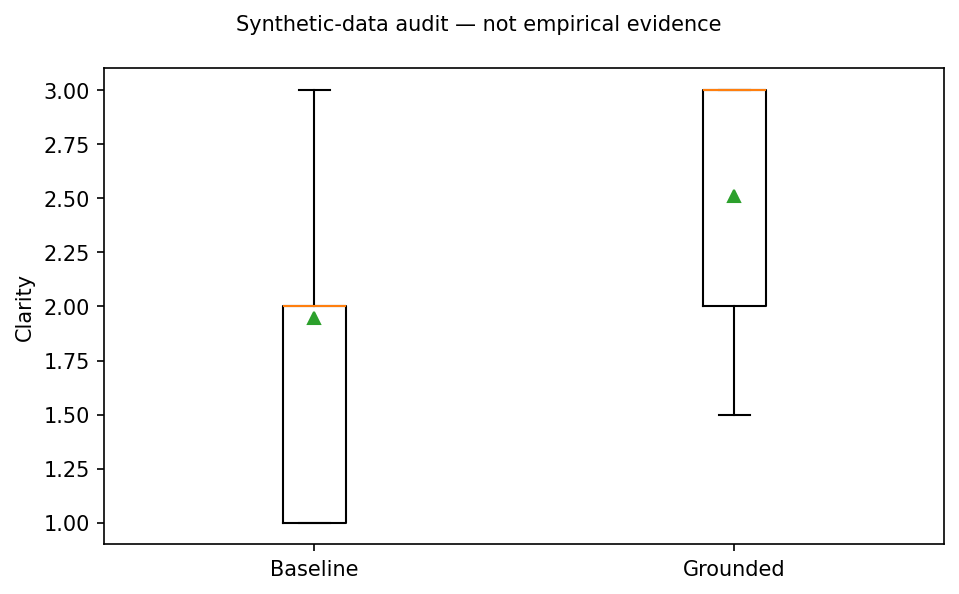

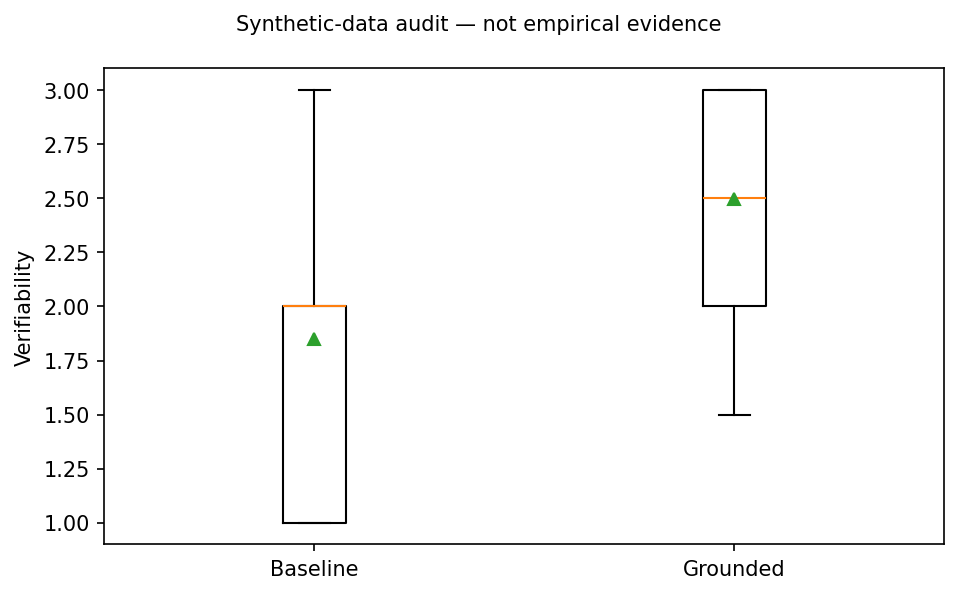

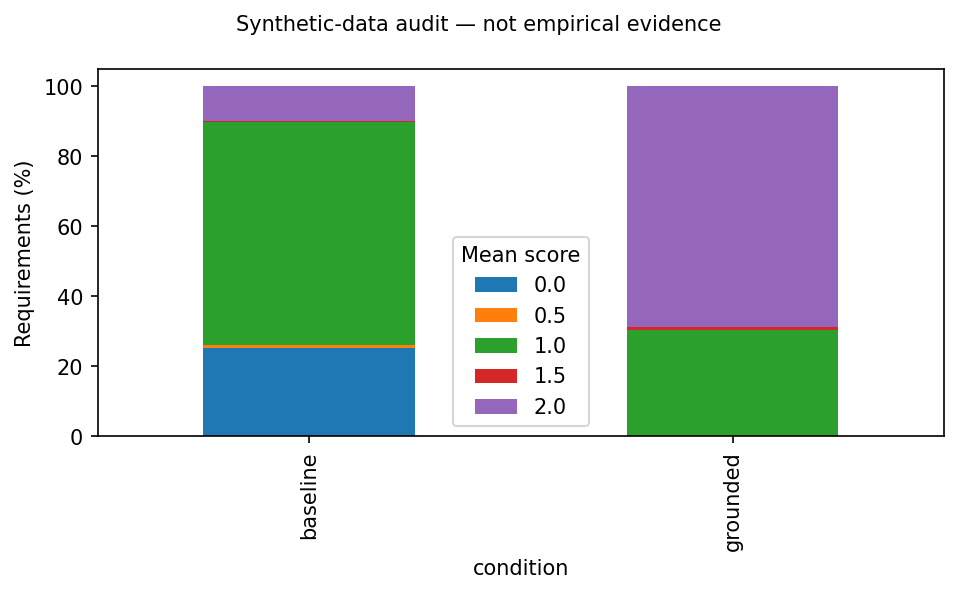

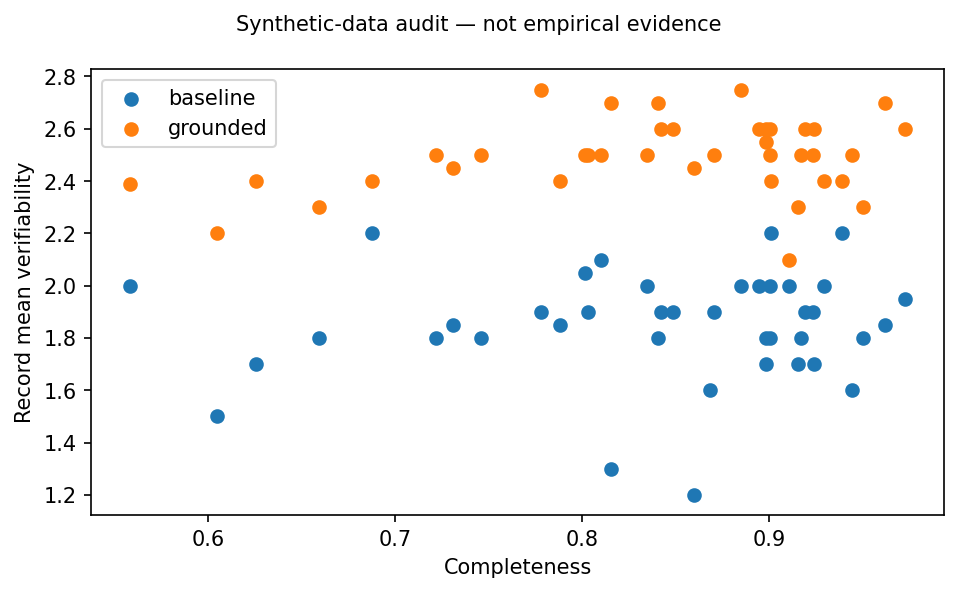

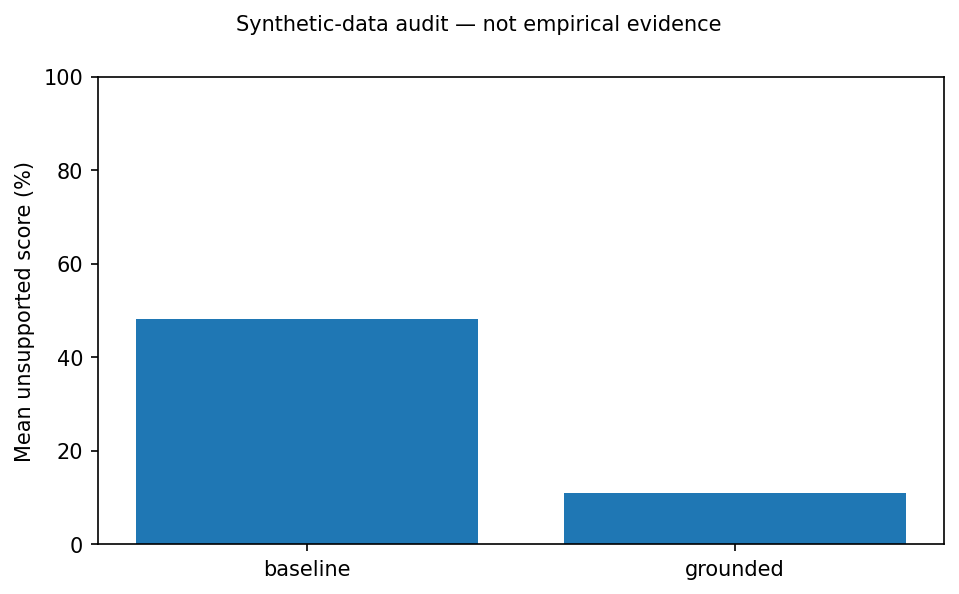

In [13]:
def savefig(fig, name):
    fig.suptitle("Synthetic-data audit — not empirical evidence", fontsize=10)
    fig.tight_layout()
    fig.savefig(OUT_DIR / f"{name}.pdf")
    display(fig)
    plt.close(fig)

for metric in ['clarity', 'verifiability']:
    fig, ax = plt.subplots(figsize=(6.5, 4))
    ax.boxplot([items.loc[items.condition == c, metric] for c in ['baseline', 'grounded']],
               showmeans=True,
               **({'tick_labels': ['Baseline', 'Grounded']} if 'tick_labels' in inspect.signature(ax.boxplot).parameters else {'labels': ['Baseline', 'Grounded']}))
    ax.set_ylabel(metric.title())
    savefig(fig, metric + '_by_condition')

fig, ax = plt.subplots(figsize=(6.5, 4))
rq2.pivot(index='condition', columns='traceability', values='pct_within_condition').fillna(0).plot.bar(stacked=True, ax=ax)
ax.set_ylabel('Requirements (%)')
ax.legend(title='Mean score')
savefig(fig, 'traceability_by_condition')

fig, ax = plt.subplots(figsize=(6.5, 4))
for c, g in record_scores.groupby('condition'):
    ax.scatter(g.completeness, g.verifiability, label=c)
ax.set_xlabel('Completeness')
ax.set_ylabel('Record mean verifiability')
ax.legend()
savefig(fig, 'completeness_vs_verifiability')

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.bar(rq4.condition, 100 * rq4.rate)
ax.set_ylabel('Mean unsupported score (%)')
ax.set_ylim(0, 100)
savefig(fig, 'unsupported_by_condition')


## 12. Supplementary publication tables, figures and sensitivity analysis
These outputs describe the supplied synthetic dataset; they are not evidence of a treatment effect. Complete-record sensitivity excludes records without ten requirements in each condition.

clarity,1.0,1.5,2.0,2.5,3.0
condition,,,,,
baseline,25.5,1.500000,52.000000,0.500000,20.500000
grounded,0.0,0.514139,47.557841,0.771208,51.156812


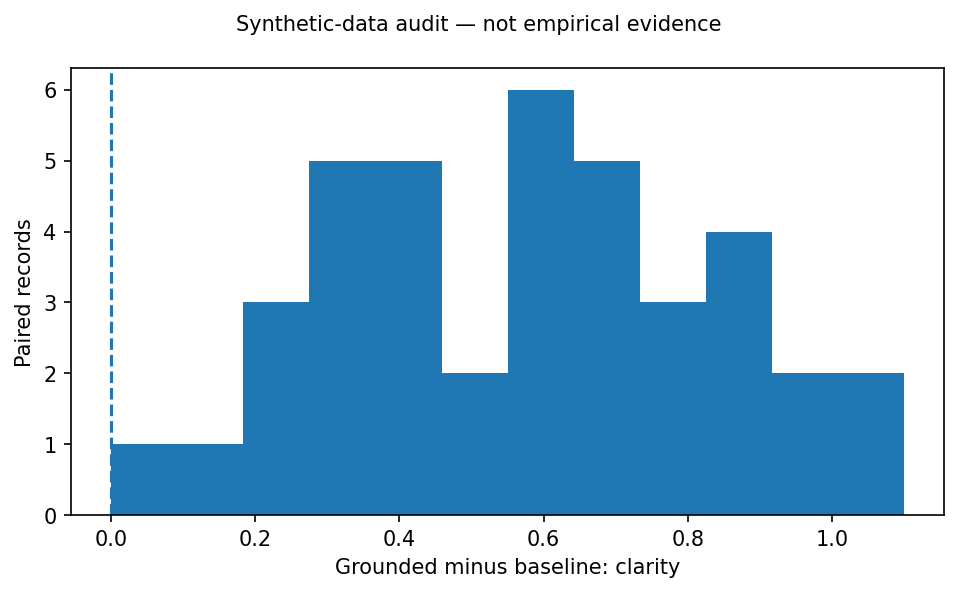

verifiability,1.0,1.5,2.0,2.5,3.0
condition,,,,,
baseline,31.25,0.500000,51.250000,1.250000,15.750000
grounded,0.00,0.514139,49.100257,1.028278,49.357326


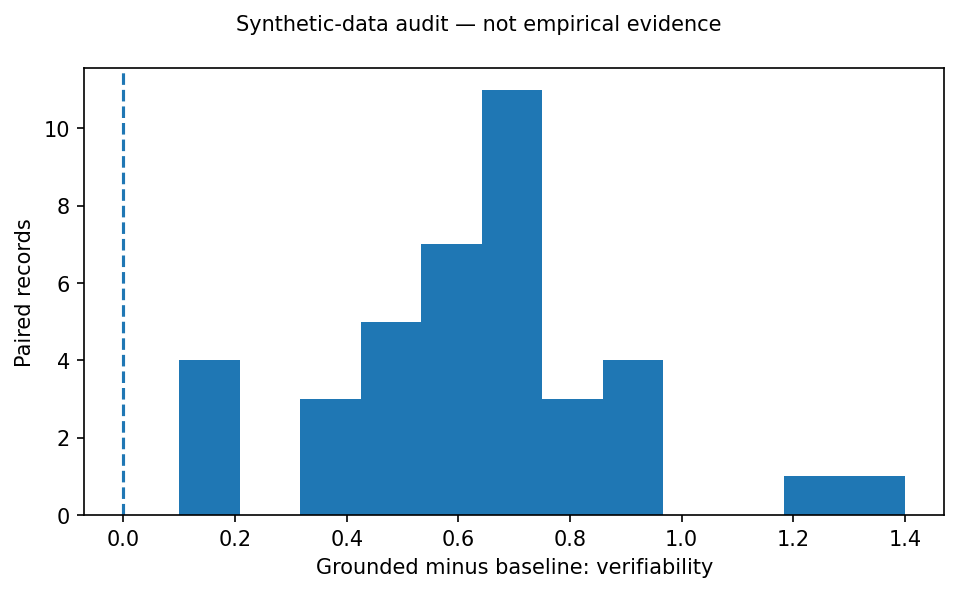

traceability,0.0,0.5,1.0,1.5,2.0
condition,,,,,
baseline,25.25,0.75,63.75000,0.250000,10.000000
grounded,0.00,0.00,30.33419,1.028278,68.637532


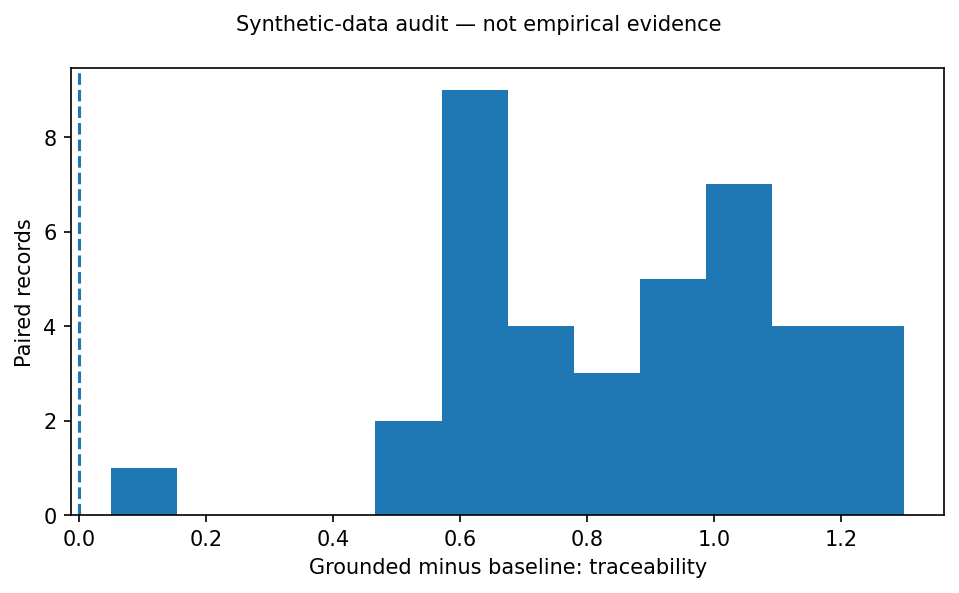

unsupported,0.0,0.5,1.0
condition,,,
baseline,50.750000,2.250000,47.000000
grounded,87.403599,3.084833,9.511568


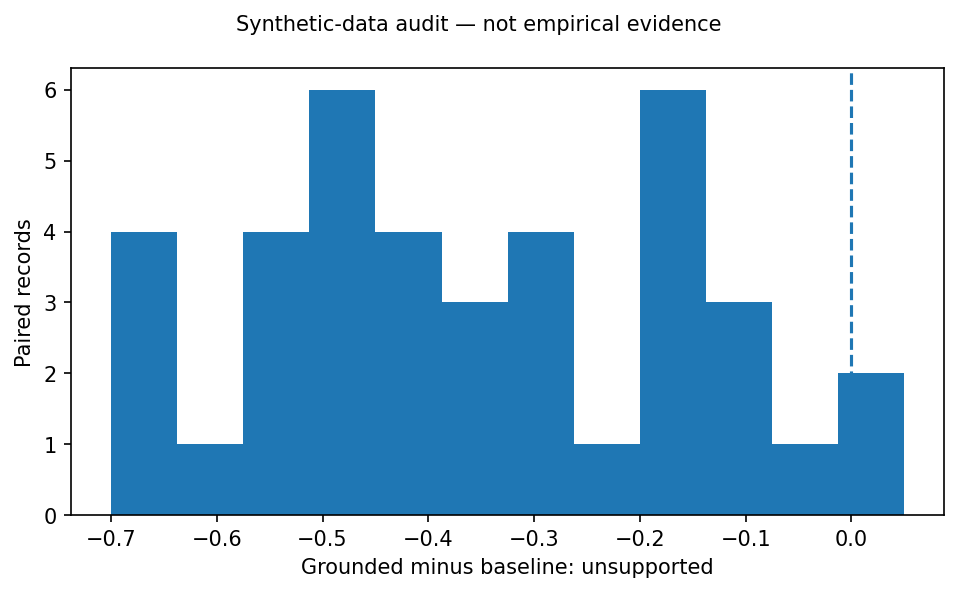

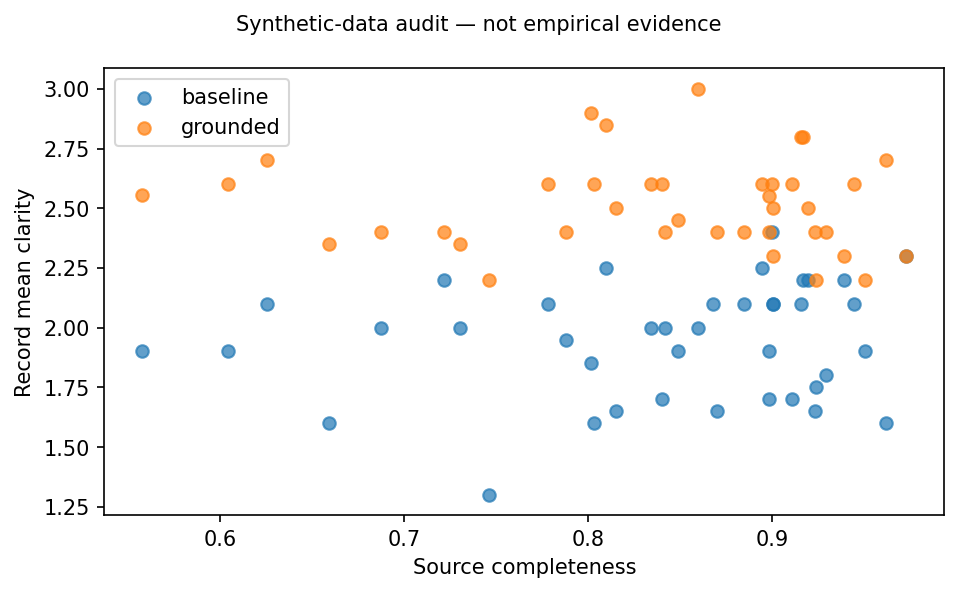

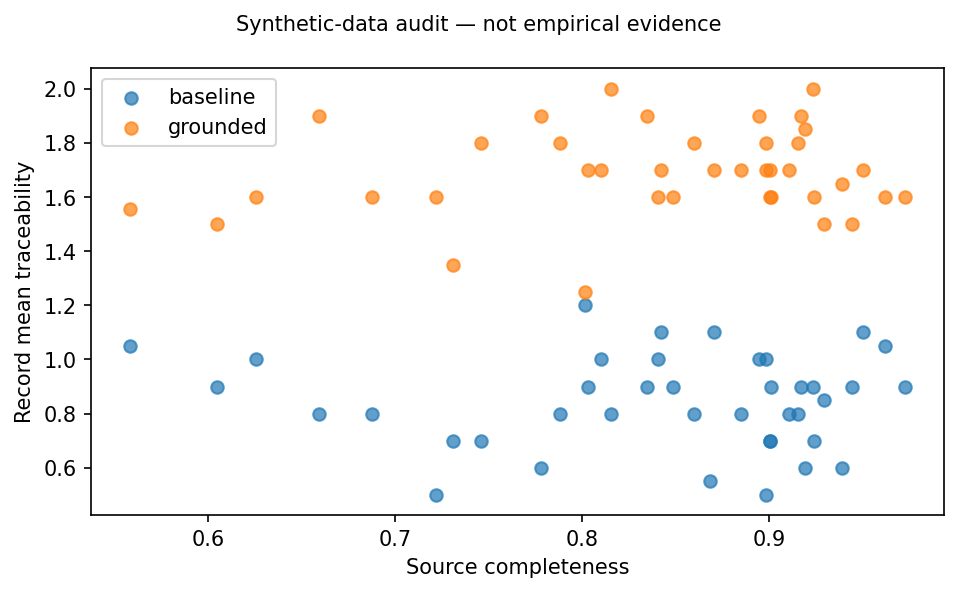

clarity                   ... unsupported                 
            count      mean median  ...       count      mean median
condition                           ...                             
baseline       38  1.942105    2.0  ...          38  0.472368    0.5
grounded       38  2.511842    2.5  ...          38  0.109211    0.1

[2 rows x 12 columns]

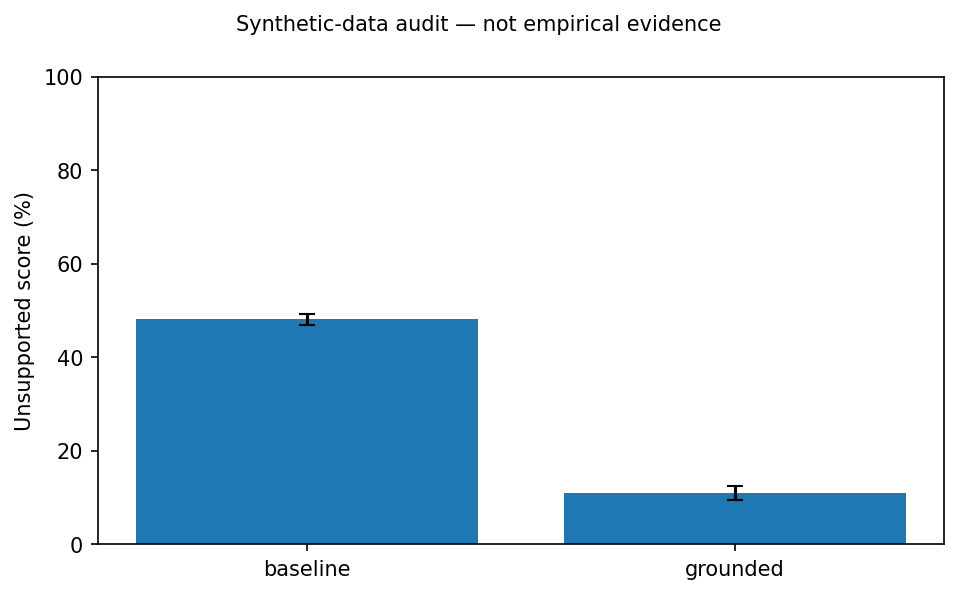

In [14]:
# Additional descriptive tables and figures: four outputs per RQ (at minimum).
# All summaries use the existing requirement-level or record-level data.
for m in ['clarity','verifiability','traceability','unsupported']:
    dist=pd.crosstab(items.condition,items[m],normalize='index')*100
    display(dist); dist.to_csv(OUT_DIR/f'{m}_score_distribution.csv')
    w=record_scores.pivot(index='record_id',columns='condition',values=m).dropna()
    w['difference']=w.grounded-w.baseline
    w.to_csv(OUT_DIR/f'{m}_paired_record_values.csv')
    fig,ax=plt.subplots(figsize=(6.5,4)); ax.hist(w.difference,bins=12); ax.axvline(0,linestyle='--'); ax.set_xlabel(f'Grounded minus baseline: {m}'); ax.set_ylabel('Paired records'); savefig(fig,f'{m}_paired_differences')
for m in ['clarity','traceability']:
    fig,ax=plt.subplots(figsize=(6.5,4))
    for c,g in record_scores.groupby('condition'): ax.scatter(g.completeness,g[m],label=c,alpha=.7)
    ax.set_xlabel('Source completeness'); ax.set_ylabel(f'Record mean {m}'); ax.legend(); savefig(fig,f'completeness_vs_{m}')
# Report coverage and sensitivity to incomplete generation without imputing missing outcomes.
complete_ids=coverage.index[coverage.eq(10).all(axis=1)]
complete_summary=record_scores[record_scores.record_id.isin(complete_ids)].groupby('condition')[metrics].agg(['count','mean','median'])
display(complete_summary); complete_summary.to_csv(OUT_DIR/'complete_record_sensitivity.csv')
# Unsupported-score bounds reflect rater disagreement, not sampling confidence intervals.
fig,ax=plt.subplots(figsize=(6.5,4)); ax.bar(rq4.condition,100*rq4.rate,yerr=np.vstack([100*(rq4.rate-rq4.lower),100*(rq4.upper-rq4.rate)]),capsize=4); ax.set_ylabel('Unsupported score (%)'); ax.set_ylim(0,100); savefig(fig,'unsupported_disagreement_bounds')


## 12. Provenance audit and export
The following audit does not run the data-writing scripts. It reproduces their documented random rating algorithm in memory and checks the characteristic requirement prefixes. Matching generated scores cannot establish independent human evaluation. Prefix matches are indicative, not authenticated generation logs.

In [15]:
rng=np.random.default_rng(SEED)
a_sim=[]
for row in key.itertuples(index=False):
    high=records.set_index('record_id').loc[row.record_id,'group']=='high'
    if row.condition=='grounded':
        c=rng.choice([2,3],p=[.45,.55]); v=rng.choice([2,3],p=[.5,.5]); t=rng.choice([1,2],p=[.3,.7]); u=rng.choice([0,1],p=[.92,.08] if high else [.88,.12])
    else:
        c=rng.choice([1,2,3],p=[.25,.55,.20]); v=rng.choice([1,2,3],p=[.35,.50,.15]); t=rng.choice([0,1,2],p=[.25,.65,.10]); u=rng.choice([0,1],p=[.60,.40] if high else [.45,.55])
    a_sim.append([row.item_id,c,v,t,u])
sim=pd.DataFrame(a_sim,columns=['item_id']+metrics)
actual=pd.read_csv(DATA_DIR/'annotations_A.csv')
audit=sim.merge(actual,on='item_id',suffixes=('_sim','_actual'),validate='one_to_one')
match=np.logical_and.reduce([audit[m+'_sim']==audit[m+'_actual'] for m in metrics])
print('Rater A rows exactly reproduced by random generator:',int(match.sum()),'/',len(match))
b_ids=set(pd.read_csv(DATA_DIR/'annotations_template_B.csv').item_id); b_sim=[]
for row in sim.itertuples(index=False):
    if row.item_id in b_ids:
        cf=rng.random()<.12; vf=rng.random()<.12; tf=rng.random()<.10; uf=rng.random()<.10
        b_sim.append([row.item_id,np.clip(row.clarity+(rng.choice([-1,1]) if cf else 0),1,3),np.clip(row.verifiability+(rng.choice([-1,1]) if vf else 0),1,3),np.clip(row.traceability+(rng.choice([-1,1]) if tf else 0),0,2),1-row.unsupported if uf else row.unsupported])
b=pd.DataFrame(b_sim,columns=['item_id']+metrics).merge(pd.read_csv(DATA_DIR/'annotations_B.csv'),on='item_id',suffixes=('_sim','_actual'),validate='one_to_one')
bmatch=np.logical_and.reduce([b[m+'_sim']==b[m+'_actual'] for m in metrics])
print('Rater B rows exactly reproduced:',int(bmatch.sum()),'/',len(bmatch))
prefixes=('The system shall operate in accordance with documented procedure:', 'The system shall implement automated processing controls to ensure that')
flag=requirements.requirement.str.startswith(prefixes)
print('Requirements with synthetic-completion template prefixes:',int(flag.sum()),'/',len(flag))
pd.DataFrame({'req_id':requirements.req_id,'template_prefix_match':flag}).to_csv(OUT_DIR/'generation_provenance_screen.csv',index=False)
print('Rubric violations:',int(((ratings.traceability==2)&(ratings.unsupported==1)).sum()))
assert all(hashlib.sha256((ROOT/r.file).read_bytes()).hexdigest()==r.sha256 for r in manifest.itertuples()), 'Input modified'
print('All input hashes unchanged.')
status={'empirical_publication_ready':False,'reason':'Simulated annotations and template-derived requirements; independent provenance required','annotation_A_exact_reproduction':int(match.sum()),'annotation_B_exact_reproduction':int(bmatch.sum()),'template_prefix_matches':int(flag.sum()),'rubric_contradictions':int(((ratings.traceability==2)&(ratings.unsupported==1)).sum())}
(OUT_DIR/'publication_status.json').write_text(json.dumps(status,indent=2))
(OUT_DIR/'requirements_reproduction.txt').write_text('\n'.join(f'{m}=={v}' for m,v in [('numpy',np.__version__),('pandas',pd.__version__),('scipy',scipy.__version__),('scikit-learn',sklearn.__version__),('matplotlib',matplotlib.__version__)]))
with zipfile.ZipFile(OUT_DIR/'verified_reanalysis_results.zip','w',zipfile.ZIP_DEFLATED) as z:
    for f in sorted(OUT_DIR.glob('*')):
        if f.is_file() and f.name != 'verified_reanalysis_results.zip' and f.suffix in {'.csv','.pdf','.json','.txt'}: z.write(f,f.name)
print('Results exported. No original CSVs changed.')


Rater A rows exactly reproduced by random generator: 789 / 789
Rater B rows exactly reproduced: 158 / 158
Requirements with synthetic-completion template prefixes: 740 / 789
Rubric violations: 53
All input hashes unchanged.
Results exported. No original CSVs changed.


## Interpretation and remaining research requirements
This notebook executes on the supplied files and preserves the original data sources. The provenance findings prevent treating the observed differences, agreement statistics and p-values as independent empirical evidence. A genuine study requires authenticated LLM generations for both conditions and independently completed, blinded human ratings following the rubric, with inconsistencies resolved. No missing observations are imputed. Exact quote matching does not establish semantic support. The selected record sample is not necessarily representative of all ATRS records.

### Publication gate (not passed)
Before an empirical submission: authenticate model outputs and generation logs, regenerate missing/template-generated items with the documented prompts, obtain independent blinded human annotations, resolve rubric contradictions without overwriting raw ratings, document calibration and sample selection, and rerun the analysis. The present dataset may only be reported as a synthetic demonstration or reproducibility audit; statistical significance and agreement are not independent evidence. Journal acceptance is not implied.